# 07: Validation analysis: uncertainty, seed ensemble, operating points
Works only from the saved val logits of the milestone-6 runs (no retraining, no GPU): patient-level bootstrap CIs, a 2-seed ensemble judged with paired CIs, calibration, frozen operating thresholds, and a descriptive AP/PA look. Nothing is selected on Hernia; the test set is never touched.

In [1]:
import json
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv

from src.bootstrap import bootstrap_auroc, bootstrap_per_class_auroc, patient_resample_counts, percentile_ci
from src.data import NIH_DISEASES, load_dev_labels
from src.metrics import SELECTION_CLASSES, auroc, macro_auroc, per_class_auroc
from src.operating_points import sens_spec, sensitivity_threshold, sha256_file, write_frozen_json, youden_threshold
from src.paths import CHECKPOINT_DIR, DEV_OUTPUT_DIR, RESEARCH_DIR, SPLIT_CSV

load_dotenv()
DATA_ROOT = Path(os.getenv("DATA_ROOT"))
NIH_DIR = DATA_ROOT / "NIH_Chest_X-Rays"

## Load saved val logits + seed ensemble

In [2]:
runs = pd.read_csv(RESEARCH_DIR / "runs.csv")
df = load_dev_labels(NIH_DIR, SPLIT_CSV)
val_df = df[df["split"] == "val"].reset_index(drop=True)
labels = val_df[NIH_DISEASES].to_numpy(dtype=float)
LOGIT_COLS = [f"logit_{d}" for d in NIH_DISEASES]

logits = {}
for r in runs.itertuples():
    saved = pd.read_csv(DEV_OUTPUT_DIR / r.run_id / "val_logits.csv")
    if not saved["Image Index"].equals(val_df["Image Index"]):
        raise RuntimeError(f"{r.run_id}: saved rows don't line up with val_df")
    logits[f"{r.pos_weight} s{r.seed}"] = saved[LOGIT_COLS].to_numpy()

MEMBERS = runs[runs["pos_weight"] == "none"].sort_values("seed")
logits["ensemble"] = np.mean([logits[f"none s{s}"] for s in MEMBERS["seed"]], axis=0)
MODELS = ["none s0", "none s1", "ensemble"]

point = pd.DataFrame({m: per_class_auroc(logits[m], labels) for m in MODELS})
per_patient = val_df.groupby("Patient ID").size()
print(f"{len(val_df):,} val images from {len(per_patient):,} patients (mean {per_patient.mean():.2f}, max {per_patient.max()} per patient)")
print("Val macro13:", {m: round(macro_auroc(point[m].to_dict()), 4) for m in MODELS})

10,542 val images from 3,501 patients (mean 3.01, max 62 per patient)
Val macro13: {'none s0': 0.8403, 'none s1': 0.841, 'ensemble': 0.8454}


## Check: weighted bootstrap AUROC == direct computation

In [3]:
z = logits["ensemble"]
one_rep, codes = patient_resample_counts(val_df["Patient ID"], n_boot=1, seed=123)
all_ones = np.ones_like(one_rep)
copied = np.repeat(np.arange(len(val_df)), one_rep[0][codes])  # the resampled dataset with images physically copied

diff_ones = max(
    abs(bootstrap_auroc(z[:, i], labels[:, i], all_ones, codes)[0] - auroc(z[:, i], labels[:, i]))
    for i in range(len(NIH_DISEASES))
)
diff_copy = max(
    abs(bootstrap_auroc(z[:, i], labels[:, i], one_rep, codes)[0] - auroc(z[copied, i], labels[copied, i]))
    for i in range(len(NIH_DISEASES))
)
print(f"All weights 1 vs auroc(): max diff {diff_ones:.1e}")
print(f"Weighted vs physically copied resample: max diff {diff_copy:.1e}")
print(f"That replicate: {len(copied):,} images from {(one_rep[0] > 0).sum():,} distinct patients")
if max(diff_ones, diff_copy) > 1e-12:
    raise RuntimeError("Weighted bootstrap AUROC doesn't match the direct computation")

All weights 1 vs auroc(): max diff 0.0e+00
Weighted vs physically copied resample: max diff 0.0e+00
That replicate: 10,614 images from 2,221 distinct patients


## Patient-level bootstrap CIs (B = 2000, seed 0)

In [4]:
N_BOOT = 2000
counts, codes = patient_resample_counts(val_df["Patient ID"], n_boot=N_BOOT, seed=0)
SEL = [NIH_DISEASES.index(c) for c in SELECTION_CLASSES]

boot = {m: bootstrap_per_class_auroc(logits[m], labels, counts, codes) for m in MODELS}
boot_macro = {m: b[:, SEL].mean(axis=1) for m, b in boot.items()}

for m in MODELS:
    lo, hi = percentile_ci(boot_macro[m])
    print(f"{m:9s} macro13 {macro_auroc(point[m].to_dict()):.4f}  95% CI [{lo:.4f}, {hi:.4f}]  SD {boot_macro[m].std():.4f}")

img_counts, img_codes = patient_resample_counts(pd.Series(np.arange(len(val_df))), n_boot=N_BOOT, seed=0)
img_macro = bootstrap_per_class_auroc(z, labels, img_counts, img_codes)[:, SEL].mean(axis=1)
print(f"\nEnsemble macro13 SD: patient-level {boot_macro['ensemble'].std():.4f} vs image-level {img_macro.std():.4f}")

lo, hi = percentile_ci(boot["ensemble"])
ci_table = pd.DataFrame({
    "auroc": point["ensemble"],
    "lo": lo,
    "hi": hi,
    "width": hi - lo,
    "val_pos": labels.sum(axis=0).astype(int),
    "pos_patients": [val_df.loc[val_df[d] == 1, "Patient ID"].nunique() for d in NIH_DISEASES],
})
print(ci_table.sort_values("width").round(4))

none s0   macro13 0.8403  95% CI [0.8314, 0.8483]  SD 0.0043
none s1   macro13 0.8410  95% CI [0.8323, 0.8490]  SD 0.0043
ensemble  macro13 0.8454  95% CI [0.8365, 0.8533]  SD 0.0042

Ensemble macro13 SD: patient-level 0.0042 vs image-level 0.0034
                     auroc      lo      hi   width  val_pos  pos_patients
Effusion            0.9101  0.8991  0.9208  0.0217      937           440
Atelectasis         0.8360  0.8216  0.8504  0.0288      979           504
Cardiomegaly        0.9383  0.9200  0.9536  0.0336      216           148
Infiltration        0.7274  0.7101  0.7449  0.0348     1661           881
Consolidation       0.8439  0.8223  0.8633  0.0410      309           187
Edema               0.9259  0.9026  0.9461  0.0435      128            79
Emphysema           0.9163  0.8900  0.9380  0.0481      174            92
Mass                0.8554  0.8270  0.8816  0.0546      414           250
Nodule              0.7822  0.7522  0.8083  0.0561      564           337
Pneumothorax

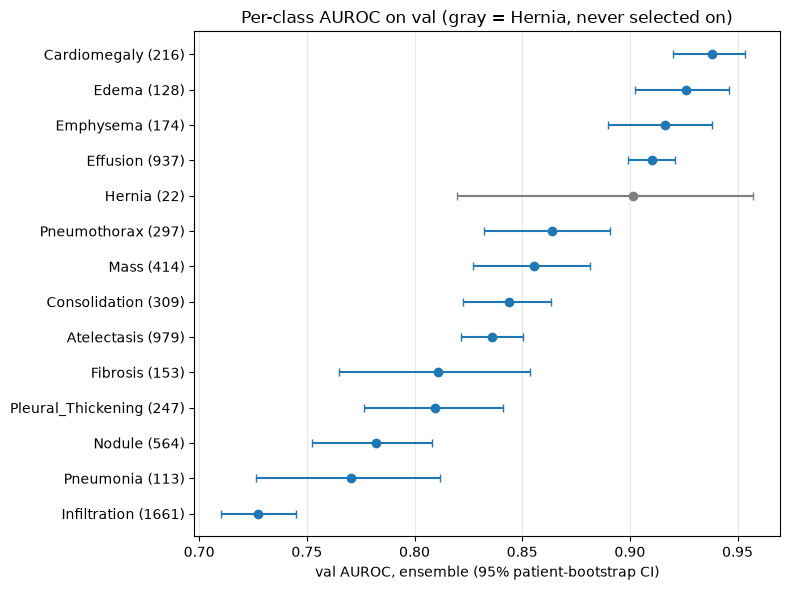

In [5]:
order = ci_table.sort_values("auroc").index
fig, ax = plt.subplots(figsize=(8, 6))
for y, cls in enumerate(order):
    row = ci_table.loc[cls]
    color = "tab:gray" if cls == "Hernia" else "tab:blue"
    ax.errorbar(row["auroc"], y, xerr=[[row["auroc"] - row["lo"]], [row["hi"] - row["auroc"]]], fmt="o", color=color, capsize=3)
ax.set_yticks(range(len(order)), [f"{c} ({ci_table.loc[c, 'val_pos']})" for c in order])
ax.set(xlabel="val AUROC, ensemble (95% patient-bootstrap CI)", title="Per-class AUROC on val (gray = Hernia, never selected on)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Decision rule: ensemble vs single model (pre-declared)
Adopt the 2-seed ensemble (mean of logits) as the primary model only if the **paired** patient-bootstrap 95% CI of (ensemble - member) macro13 has its lower bound > 0 for **both** members. Otherwise the primary model is `none s0`. Same resamples for every model (paired).

In [6]:
rows = []
for a, b in [("ensemble", "none s0"), ("ensemble", "none s1"), ("none s1", "none s0")]:
    lo, hi = percentile_ci(boot_macro[a] - boot_macro[b])
    rows.append({
        "comparison": f"{a} - {b}",
        "point": macro_auroc(point[a].to_dict()) - macro_auroc(point[b].to_dict()),
        "lo": lo,
        "hi": hi,
    })
paired = pd.DataFrame(rows).set_index("comparison")
adopt_ensemble = bool((paired["lo"].iloc[:2] > 0).all())
print(paired.round(4))
print(f"\nAdopt ensemble: {adopt_ensemble}")

unpaired = boot_macro["ensemble"] - np.random.default_rng(1).permutation(boot_macro["none s0"])
print(f"Unpaired CI for ensemble - none s0 (wrong, for contrast): {percentile_ci(unpaired).round(4)}")

gain = point["ensemble"] - point[["none s0", "none s1"]].mean(axis=1)
print(f"Ensemble beats the mean of its members in {int((gain[SELECTION_CLASSES] > 0).sum())} / 13 selection classes; "
      f"gain range {gain[SELECTION_CLASSES].min():+.4f} to {gain[SELECTION_CLASSES].max():+.4f}")

                     point      lo      hi
comparison                                
ensemble - none s0  0.0051  0.0035  0.0069
ensemble - none s1  0.0044  0.0027  0.0060
none s1 - none s0   0.0007 -0.0025  0.0041

Adopt ensemble: True
Unpaired CI for ensemble - none s0 (wrong, for contrast): [-0.0068  0.0176]
Ensemble beats the mean of its members in 13 / 13 selection classes; gain range +0.0026 to +0.0064


## Re-check of the milestone 6 decision with paired CIs (no decision changes here)

In [7]:
for s in MEMBERS["seed"]:
    sqrt_macro = bootstrap_per_class_auroc(logits[f"sqrt s{s}"], labels, counts, codes)[:, SEL].mean(axis=1)
    lo, hi = percentile_ci(sqrt_macro - boot_macro[f"none s{s}"])
    print(f"seed {s}: sqrt - none = {macro_auroc(per_class_auroc(logits[f'sqrt s{s}'], labels)) - macro_auroc(point[f'none s{s}'].to_dict()):+.4f}  "
          f"paired 95% CI [{lo:+.4f}, {hi:+.4f}]")

seed 0: sqrt - none = -0.0023  paired 95% CI [-0.0054, +0.0009]
seed 1: sqrt - none = -0.0037  paired 95% CI [-0.0069, -0.0006]


## Calibration: members vs ensemble

In [8]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def ece(p, y, n_bins=10):
    edges = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    bins = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, n_bins - 1)
    return float(sum((bins == b).mean() * abs(p[bins == b].mean() - y[bins == b].mean()) for b in range(n_bins)))


prob_mean = np.mean([sigmoid(logits[f"none s{s}"]) for s in MEMBERS["seed"]], axis=0)
candidates = {m: sigmoid(logits[m]) for m in MODELS}
candidates["ensemble (prob mean)"] = prob_mean

rows = []
for name, p in candidates.items():
    rows.append({
        "model": name,
        "BCE": float(np.mean(-(labels * np.log(p) + (1 - labels) * np.log(1 - p)))),
        "Brier": float(np.mean((p - labels) ** 2)),
        "ECE (mean of 14)": float(np.mean([ece(p[:, i], labels[:, i]) for i in range(len(NIH_DISEASES))])),
        "mean pred / prevalence (median of 14)": float(np.median(p.mean(axis=0) / labels.mean(axis=0))),
    })
print(pd.DataFrame(rows).set_index("model").round(5))

                          BCE    Brier  ECE (mean of 14)  \
model                                                      
none s0               0.12402  0.03324           0.00594   
none s1               0.12407  0.03323           0.00681   
ensemble              0.12280  0.03296           0.00586   
ensemble (prob mean)  0.12268  0.03295           0.00555   

                      mean pred / prevalence (median of 14)  
model                                                        
none s0                                             1.01246  
none s1                                             0.97922  
ensemble                                            0.98245  
ensemble (prob mean)                                1.00945  


## Operating points (criterion pre-declared)
Per class, on the primary model's val logits: the **highest threshold with val sensitivity >= 0.90** (depends only on the positives' scores, so it is unaffected by the prevalence shift on test). Youden's J is shown for comparison only. Rule everywhere: positive if score >= threshold.

In [9]:
TARGET_SENS = 0.90
rows = []
for i, d in enumerate(NIH_DISEASES):
    row = {"val_pos": int(labels[:, i].sum())}
    for name, t in [("sens90", sensitivity_threshold(z[:, i], labels[:, i], TARGET_SENS)), ("youden", youden_threshold(z[:, i], labels[:, i]))]:
        sens, spec = sens_spec(z[:, i], labels[:, i], t)
        row |= {f"{name}_logit": t, f"{name}_sens": sens, f"{name}_spec": spec, f"{name}_ppv": labels[z[:, i] >= t, i].mean()}
    rows.append(row)
thresholds = pd.DataFrame(rows, index=NIH_DISEASES)
print(thresholds.round(3))

                    val_pos  sens90_logit  sens90_sens  sens90_spec  \
Atelectasis             979        -3.225        0.901        0.586   
Cardiomegaly            216        -4.140        0.903        0.828   
Consolidation           309        -4.070        0.903        0.611   
Edema                   128        -4.038        0.906        0.839   
Effusion                937        -3.030        0.901        0.749   
Emphysema               174        -5.043        0.902        0.746   
Fibrosis                153        -5.163        0.902        0.510   
Hernia                   22        -6.338        0.909        0.828   
Infiltration           1661        -2.302        0.900        0.364   
Mass                    414        -4.482        0.901        0.559   
Nodule                  564        -4.016        0.901        0.390   
Pleural_Thickening      247        -4.720        0.903        0.497   
Pneumonia               113        -5.363        0.903        0.442   
Pneumo

In [10]:
N_STAB = 300
achieved = {"sens90": [], "youden": []}
for c in counts[:N_STAB]:
    idx = np.repeat(np.arange(len(val_df)), c[codes])
    for name, pick in [("sens90", lambda s, y: sensitivity_threshold(s, y, TARGET_SENS)), ("youden", youden_threshold)]:
        ts = [pick(z[idx, i], labels[idx, i]) for i in range(len(NIH_DISEASES))]
        achieved[name].append([sens_spec(z[:, i], labels[:, i], t)[0] for i, t in enumerate(ts)])

stability = pd.DataFrame(index=NIH_DISEASES)
for name, a in achieved.items():
    lo, hi = np.percentile(np.array(a), [5, 95], axis=0)
    stability[f"{name} sens 5%"] = lo
    stability[f"{name} sens 95%"] = hi
    stability[f"{name} range"] = hi - lo
print("Full-val sensitivity of thresholds picked on patient-bootstrap resamples (5th-95th percentile):")
print(stability.round(3))
print("\nMedian range:", stability[["sens90 range", "youden range"]].median().round(3).to_dict())

Full-val sensitivity of thresholds picked on patient-bootstrap resamples (5th-95th percentile):
                    sens90 sens 5%  sens90 sens 95%  sens90 range  \
Atelectasis                  0.882            0.920         0.038   
Cardiomegaly                 0.861            0.935         0.074   
Consolidation                0.864            0.926         0.062   
Edema                        0.859            0.938         0.078   
Effusion                     0.880            0.917         0.036   
Emphysema                    0.856            0.937         0.080   
Fibrosis                     0.843            0.948         0.105   
Hernia                       0.773            1.000         0.227   
Infiltration                 0.886            0.913         0.028   
Mass                         0.867            0.928         0.061   
Nodule                       0.874            0.927         0.053   
Pleural_Thickening           0.866            0.931         0.065   
Pneumon

## Freeze the operating points
Written once to `research/operating_points.json` (committed): members with checkpoint + val-logit SHA-256, the score definition, the rule, and the thresholds. Re-running with identical content is a no-op; different content raises.

In [11]:
primary_members = MEMBERS if adopt_ensemble else MEMBERS[MEMBERS["seed"] == 0]
z_primary = logits["ensemble"] if adopt_ensemble else logits["none s0"]

frozen = {
    "version": 1,
    "made_by": "notebooks/07_validation.ipynb",
    "score": "mean of member logits" if adopt_ensemble else "member logit",
    "members": [
        {
            "run_id": r.run_id,
            "checkpoint": f"checkpoints/{r.run_id}.pt",
            "checkpoint_sha256": sha256_file(CHECKPOINT_DIR / f"{r.run_id}.pt"),
            "val_logits_sha256": sha256_file(DEV_OUTPUT_DIR / r.run_id / "val_logits.csv"),
        }
        for r in primary_members.itertuples()
    ],
    "rule": "positive if score >= threshold",
    "criterion": f"highest threshold with val sensitivity >= {TARGET_SENS}",
    "thresholds": {d: sensitivity_threshold(z_primary[:, i], labels[:, i], TARGET_SENS) for i, d in enumerate(NIH_DISEASES)},
}
path = RESEARCH_DIR / "operating_points.json"
write_frozen_json(frozen, path)

reloaded = json.loads(path.read_text())
val_sens = {d: sens_spec(z_primary[:, i], labels[:, i], reloaded["thresholds"][d])[0] for i, d in enumerate(NIH_DISEASES)}
if min(val_sens.values()) < TARGET_SENS:
    raise RuntimeError("A reloaded threshold misses the sensitivity target on val")
print(f"Wrote {path.name}: {len(reloaded['thresholds'])} thresholds, members {[m['run_id'] for m in reloaded['members']]}")
print(f"Reloaded val sensitivity: min {min(val_sens.values()):.4f}, max {max(val_sens.values()):.4f}")

Wrote operating_points.json: 14 thresholds, members ['20261109-1844_none_s0', '20261109-1858_none_s1']
Reloaded val sensitivity: min 0.9001, max 0.9091


## First look at the view confound (AP vs PA), descriptive only
Within-view AUROC compares positives and negatives of the same view. Nothing is selected on this.

In [12]:
is_ap = (val_df["View Position"] == "AP").to_numpy()
rows = []
for i, d in enumerate(NIH_DISEASES):
    row = {"pooled": point.loc[d, "ensemble"]}
    for view, mask in [("AP", is_ap), ("PA", ~is_ap)]:
        row[f"pos_{view}"] = int(labels[mask, i].sum())
        row[f"prev_{view}"] = labels[mask, i].mean()
        row[f"auc_{view}"] = auroc(z[mask, i], labels[mask, i])
    row["AP/PA prev"] = row["prev_AP"] / row["prev_PA"]
    row["pooled - best view"] = row["pooled"] - max(row["auc_AP"], row["auc_PA"])
    row["logit AUROC for AP view"] = auroc(z[:, i], is_ap)
    rows.append(row)
by_view = pd.DataFrame(rows, index=NIH_DISEASES)
print(f"Val views: AP {is_ap.sum():,}, PA {(~is_ap).sum():,}")
print(by_view.drop(columns=["prev_AP", "prev_PA"]).round(3))

Val views: AP 3,417, PA 7,125
                    pooled  pos_AP  auc_AP  pos_PA  auc_PA  AP/PA prev  \
Atelectasis          0.836     423   0.793     556   0.852       1.586   
Cardiomegaly         0.938      54   0.931     162   0.943       0.695   
Consolidation        0.844     163   0.801     146   0.850       2.328   
Edema                0.926     113   0.852      15   0.886      15.708   
Effusion             0.910     345   0.873     592   0.926       1.215   
Emphysema            0.916      68   0.930     106   0.905       1.338   
Fibrosis             0.811      19   0.780     134   0.790       0.296   
Hernia               0.901       3   0.767      19   0.928       0.329   
Infiltration         0.727     645   0.773    1016   0.692       1.324   
Mass                 0.855     138   0.835     276   0.864       1.043   
Nodule               0.782     170   0.800     394   0.774       0.900   
Pleural_Thickening   0.809      47   0.759     200   0.816       0.490   
Pneumoni

In [13]:
for cls in ["Edema", "Fibrosis"]:
    i = NIH_DISEASES.index(cls)
    pooled = bootstrap_auroc(z[:, i], labels[:, i], counts, codes)
    for view, mask in [("AP", is_ap), ("PA", ~is_ap)]:
        within = bootstrap_auroc(z[mask, i], labels[mask, i], counts, codes[mask])
        lo, hi = percentile_ci(pooled - within)
        print(f"{cls}: pooled - {view} = {by_view.loc[cls, 'pooled'] - by_view.loc[cls, f'auc_{view}']:+.3f}  paired 95% CI [{lo:+.3f}, {hi:+.3f}]")

Edema: pooled - AP = +0.074  paired 95% CI [+0.048, +0.100]
Edema: pooled - PA = +0.040  paired 95% CI [-0.027, +0.130]
Fibrosis: pooled - AP = +0.031  paired 95% CI [-0.105, +0.181]
Fibrosis: pooled - PA = +0.021  paired 95% CI [-0.019, +0.051]


## Validation decisions
- Inputs: saved val logits of the 4 milestone-6 runs (commit `97cf6d5`); 10,542 val images, 3,501 patients (mean 3.01, max 62 images per patient). No retraining, test untouched, nothing selected on Hernia.
- **CIs: patient-level bootstrap**, 2,000 resamples (seed 0), percentile 95% CIs, the same resamples for every model (paired). The weighted implementation matches direct and physically copied computation exactly (max diff 0). Image-level bootstrap would understate uncertainty: macro13 SD 0.0034 vs 0.0042 (patient).
- Val macro13 (95% CI): none s0 0.8403 [0.8314, 0.8483], none s1 0.8410 [0.8323, 0.8490], ensemble 0.8454 [0.8365, 0.8533]. Per-class CI width follows positive *patients*: Effusion 0.022 (440) to Hernia 0.138 (14).
- **Decision: primary model = 2-seed ensemble (mean of logits, none s0 + s1).** Pre-declared rule (paired lower bound > 0 vs both members) met: ensemble - s0 +0.0051 [0.0035, 0.0069], ensemble - s1 +0.0044 [0.0027, 0.0060]. Gains in 13 / 13 selection classes (+0.0026 to +0.0064). The unpaired CI would be [-0.0068, 0.0176]: pairing is what makes the comparison informative.
- Seed noise: s1 - s0 +0.0007 [-0.0025, 0.0041].
- M6 re-check (no change): sqrt - none paired CI [-0.0054, +0.0009] (seed 0), [-0.0069, -0.0006] (seed 1). Consistent with "no benefit from sqrt weighting".
- Calibration: the ensemble is slightly better than either member (BCE 0.1228 vs 0.1240 / 0.1241; Brier 0.0330 vs 0.0332); ECE about 0.006 for all. The probability mean is marginally better (BCE 0.12268) but not adopted: the difference is negligible, and the logit mean is the frozen score.
- **Decision: operating point = highest threshold with val sensitivity >= 0.90 per class** (prevalence-free; test prevalence is shifted). Val specificity at that point: 0.36 (Infiltration) to 0.84 (Edema). Youden rejected: on patient resamples its achieved sensitivity varies about twice as much (median 5-95% range 0.13 vs 0.07; Pneumonia 0.56-0.84). PPV depends on prevalence and is reported only descriptively.
- **Frozen: `research/operating_points.json`** (write-once): members, checkpoint + val-logit SHA-256, score, rule (`>=`), 14 thresholds. Reloaded val sensitivity 0.9001-0.9091.
- View confound (descriptive only): Edema pooled AUROC 0.926 exceeds both AP 0.852 and PA 0.886 (AP/PA prevalence 15.7x; the Edema logit predicts AP view with AUROC 0.817). Pooled - AP +0.074 [0.048, 0.100]; pooled - PA +0.040 [-0.027, 0.130] (15 PA positives). Fibrosis shows the reverse pattern (pooled 0.811 vs 0.780 / 0.790). Candidate pre-declared stratified analysis for the plan.
- Caveat: val chose the epoch, pos_weight, the ensemble, and the thresholds, so val numbers are optimistic; expect test sensitivity at the frozen thresholds to land somewhat below 0.90 even without shift.
- Carried forward: before test, the test entry point must re-run inference on val from the hashed checkpoints and reproduce the saved val logits (same AUROCs, thresholds still give sensitivity >= 0.90), so the test-time inference path is proven identical.